In [3]:
import polars as pl 
import matplotlib.pyplot as plt 

data = pl.read_excel("../../data/online_retail_II.xlsx", sheet_id=0, engine='calamine', schema_overrides= {"Invoice": pl.String})

In [4]:
# dataset = []

# for name, df in data.items():
#     df = df.with_columns(pl.col("Invoice").cast(pl.String).str.strip_chars())

#     dataset.append(df) 


# data = pl.concat(dataset)

In [5]:
data = pl.concat(data.values())

In [6]:
data.filter(pl.col('Invoice').str.starts_with('C'))

Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
str,str,str,i64,datetime[ms],f64,i64,str
"""C489449""","""22087""","""PAPER BUNTING WHITE LACE""",-12,2009-12-01 10:33:00,2.95,16321,"""Australia"""
"""C489449""","""85206A""","""CREAM FELT EASTER EGG BASKET""",-6,2009-12-01 10:33:00,1.65,16321,"""Australia"""
"""C489449""","""21895""","""POTTING SHED SOW 'N' GROW SET""",-4,2009-12-01 10:33:00,4.25,16321,"""Australia"""
"""C489449""","""21896""","""POTTING SHED TWINE""",-6,2009-12-01 10:33:00,2.1,16321,"""Australia"""
"""C489449""","""22083""","""PAPER CHAIN KIT RETRO SPOT""",-12,2009-12-01 10:33:00,2.95,16321,"""Australia"""
…,…,…,…,…,…,…,…
"""C581490""","""23144""","""ZINC T-LIGHT HOLDER STARS SMAL…",-11,2011-12-09 09:57:00,0.83,14397,"""United Kingdom"""
"""C581499""","""M""","""Manual""",-1,2011-12-09 10:28:00,224.69,15498,"""United Kingdom"""
"""C581568""","""21258""","""VICTORIAN SEWING BOX LARGE""",-5,2011-12-09 11:57:00,10.95,15311,"""United Kingdom"""


In [7]:
data.filter(pl.col('Price') < 0)

Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
str,str,str,i64,datetime[ms],f64,i64,str
"""A506401""","""B""","""Adjust bad debt""",1,2010-04-29 13:36:00,-53594.36,null,"""United Kingdom"""
"""A516228""","""B""","""Adjust bad debt""",1,2010-07-19 11:24:00,-44031.79,null,"""United Kingdom"""
"""A528059""","""B""","""Adjust bad debt""",1,2010-10-20 12:04:00,-38925.87,null,"""United Kingdom"""
"""A563186""","""B""","""Adjust bad debt""",1,2011-08-12 14:51:00,-11062.06,null,"""United Kingdom"""
"""A563187""","""B""","""Adjust bad debt""",1,2011-08-12 14:52:00,-11062.06,null,"""United Kingdom"""


according to the data source invoice that would start with C are cancellations, but this dataset does not contain any. therefore we would assume that Price < 0 are cancellations

another thing to look at here is there are only 5 cancellations, and all of them have just the stock code of B and description as adjust bad debt

In [8]:
data.filter(pl.col('StockCode') == 'B')

Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
str,str,str,i64,datetime[ms],f64,i64,str
"""A506401""","""B""","""Adjust bad debt""",1,2010-04-29 13:36:00,-53594.36,null,"""United Kingdom"""
"""A516228""","""B""","""Adjust bad debt""",1,2010-07-19 11:24:00,-44031.79,null,"""United Kingdom"""
"""A528059""","""B""","""Adjust bad debt""",1,2010-10-20 12:04:00,-38925.87,null,"""United Kingdom"""
"""A563185""","""B""","""Adjust bad debt""",1,2011-08-12 14:50:00,11062.06,null,"""United Kingdom"""
"""A563186""","""B""","""Adjust bad debt""",1,2011-08-12 14:51:00,-11062.06,null,"""United Kingdom"""
"""A563187""","""B""","""Adjust bad debt""",1,2011-08-12 14:52:00,-11062.06,null,"""United Kingdom"""


there is another row that contains this, but no negative sign then the original assumption of treating negative prices as returns does not really hold, rather they look like adjusting for accounting...

In [9]:
data.is_duplicated().sum()

67242

it seems inflated because is_duplicated flags both the first occurrence and other occurrences as true

In [10]:
data.shape[0] - data.unique(keep='first').shape[0]

34335

In [11]:
data_1 = data.unique(keep='first')

In [12]:
data_1.shape

(1033036, 8)

In [13]:
data_1.null_count()

Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
u32,u32,u32,u32,u32,u32,u32,u32
0,0,4275,0,0,0,235151,0


In [14]:
data_1.filter(pl.col('Invoice').str.starts_with('C'))

Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
str,str,str,i64,datetime[ms],f64,i64,str
"""C518669""","""22077""","""6 RIBBONS RUSTIC CHARM""",-12,2010-08-10 15:16:00,1.65,13004,"""United Kingdom"""
"""C496116""","""M""","""Manual""",-1,2010-01-29 11:05:00,8985.6,17949,"""United Kingdom"""
"""C509036""","""84795D""","""SEASIDE STRIPE HAMMOCK""",-1,2010-05-20 09:32:00,6.95,15614,"""United Kingdom"""
"""C517068""","""22329""","""ROUND CONTAINER SET OF 5 RETRO…",-12,2010-07-26 13:46:00,1.65,16555,"""United Kingdom"""
"""C540164""","""35400""","""WOODEN BOX ADVENT CALENDAR """,-2,2011-01-05 12:02:00,8.95,14911,"""EIRE"""
…,…,…,…,…,…,…,…
"""C543636""","""22727""","""ALARM CLOCK BAKELIKE RED """,-1,2011-02-10 16:34:00,3.75,13767,"""United Kingdom"""
"""C569985""","""71053""","""WHITE METAL LANTERN""",-8,2011-10-06 19:51:00,3.75,15365,"""United Kingdom"""
"""C504468""","""22198""","""LARGE POPCORN HOLDER """,-3,2010-04-13 17:40:00,1.65,15329,"""United Kingdom"""


for the lingering null how can we deal with them

In [15]:
null_description = data_1.filter(pl.col('Description').is_null())

In [16]:
null_description

Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
str,str,str,i64,datetime[ms],f64,i64,str
"""540982""","""22323""",null,1,2011-01-12 15:35:00,0.0,null,"""United Kingdom"""
"""549145""","""21421""",null,26,2011-04-06 15:28:00,0.0,null,"""United Kingdom"""
"""507683""","""72753C""",null,-3,2010-05-11 09:48:00,0.0,null,"""United Kingdom"""
"""495213""","""21406""",null,-8,2010-01-21 17:02:00,0.0,null,"""United Kingdom"""
"""500544""","""84427B""",null,2,2010-03-08 15:32:00,0.0,null,"""United Kingdom"""
…,…,…,…,…,…,…,…
"""496645""","""21855""",null,-1,2010-02-03 12:03:00,0.0,null,"""United Kingdom"""
"""558448""","""22163""",null,-90,2011-06-29 13:40:00,0.0,null,"""United Kingdom"""
"""500888""","""37450""",null,-6,2010-03-10 16:06:00,0.0,null,"""United Kingdom"""


In [17]:
null_decription_code = null_description.select('StockCode').unique()

In [18]:
null_description_code = null_decription_code.to_series().to_list()

In [19]:
data_1.filter(pl.col('StockCode').is_in(null_description_code))

Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
str,str,str,i64,datetime[ms],f64,i64,str
"""528618""","""21174""","""POTTERING IN THE SHED METAL SI…",1,2010-10-22 17:07:00,1.95,13263,"""United Kingdom"""
"""573552""","""22621""","""TRADITIONAL KNITTING NANCY""",12,2011-10-31 13:43:00,1.65,13203,"""United Kingdom"""
"""504838""","""48187""","""DOOR MAT NEW ENGLAND""",2,2010-04-16 15:18:00,7.49,15078,"""United Kingdom"""
"""544067""","""22698""","""PINK REGENCY TEACUP AND SAUCER""",8,2011-02-15 14:02:00,2.95,16431,"""United Kingdom"""
"""490400""","""79323P""","""PINK CHERRY LIGHTS""",8,2009-12-06 10:41:00,6.75,16104,"""United Kingdom"""
…,…,…,…,…,…,…,…
"""529847""","""16212""","""FUNKY GIRLZ ASST MAGNETIC MEMO…",3,2010-10-31 13:23:00,0.65,13050,"""United Kingdom"""
"""575649""","""85066""","""CREAM SWEETHEART MINI CHEST""",1,2011-11-10 14:23:00,12.75,null,"""United Kingdom"""
"""539631""","""22909""","""SET OF 20 VINTAGE CHRISTMAS NA…",1,2010-12-20 15:03:00,1.66,null,"""United Kingdom"""


we can fill those back in since the description for stock code do exist for the null description else where
but let us check whether the description is consistent everywhere first

In [20]:
mapping_check = (
    data_1.filter(pl.col("Description").is_not_null())
    .group_by("StockCode")
    .agg(
        pl.col("Description").n_unique().alias("n_names"),
        pl.len().alias("records"),
    )
)

print(
    mapping_check.filter(pl.col("n_names") > 1)
    .sort("n_names", descending=True)
)

shape: (1_232, 3)
┌───────────┬─────────┬─────────┐
│ StockCode ┆ n_names ┆ records │
│ ---       ┆ ---     ┆ ---     │
│ str       ┆ u32     ┆ u32     │
╞═══════════╪═════════╪═════════╡
│ 20713     ┆ 9       ┆ 1345    │
│ 22734     ┆ 7       ┆ 786     │
│ 22423     ┆ 7       ┆ 4305    │
│ 21181     ┆ 7       ┆ 1850    │
│ 23084     ┆ 7       ┆ 1038    │
│ …         ┆ …       ┆ …       │
│ 21175     ┆ 2       ┆ 1683    │
│ 84763     ┆ 2       ┆ 172     │
│ 22680     ┆ 2       ┆ 240     │
│ 20622     ┆ 2       ┆ 128     │
│ 21035     ┆ 2       ┆ 941     │
└───────────┴─────────┴─────────┘


In [21]:
data_1.filter(
    pl.col("StockCode") == "20713"
).group_by("Description").agg(
    pl.len().alias("count"),
    pl.col("InvoiceDate").min().alias("first_seen"),
    pl.col("InvoiceDate").max().alias("last_seen"),
).sort("count", descending=True)

Description,count,first_seen,last_seen
str,u32,datetime[ms],datetime[ms]
"""JUMBO BAG OWLS""",1337,2009-12-01 12:13:00,2011-12-09 12:19:00
null,5,2010-08-26 12:26:00,2011-03-29 17:11:00
"""Marked as 23343""",1,2011-10-26 14:14:00,2011-10-26 14:14:00
"""found""",1,2011-10-18 11:27:00,2011-10-18 11:27:00
"""wrongly marked 23343""",1,2011-10-24 17:01:00,2011-10-24 17:01:00
"""Found""",1,2011-10-24 10:53:00,2011-10-24 10:53:00
"""wrongly marked. 23343 in box""",1,2011-07-14 14:27:00,2011-07-14 14:27:00
"""wrongly coded 23343""",1,2011-10-27 15:36:00,2011-10-27 15:36:00
"""missing""",1,2010-07-05 12:06:00,2010-07-05 12:06:00


In [22]:
data_1.shape

(1033036, 8)

Interesting, lets do this

before we do imputation, we will work with making the descritpion consistent

so, first lets make everything upper case
then we will keep the rows which contain the description with the most number of occurrences and are non null
then do the imputation

also we need to manage these values some how
we can maybe remove descriptions such as found and missing, but keep ones like wrongly coded or wrongly marked
and replace the stock with the integer+string in the string...
we would then need to look and find for bad inputs in stock id and if manageable then manually change them

first lets manage operational messages

In [23]:
operational_pattern = operational_pattern = (
    r"(?i)(wrongly coded|wrongly marked|marked as)"
)

data_2 = data_1.with_columns(pl.col('Description').str.contains(operational_pattern).fill_null(False).alias('is_operational_annotation'))

In [24]:
data_2.filter(pl.col('is_operational_annotation') == True)

Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,is_operational_annotation
str,str,str,i64,datetime[ms],f64,i64,str,bool
"""569830""","""23343""","""wrongly coded 20713""",800,2011-10-06 12:38:00,0.0,null,"""United Kingdom""",true
"""575722""","""85123A""","""wrongly marked carton 22804""",-256,2011-11-10 18:20:00,0.0,null,"""United Kingdom""",true
"""572548""","""23343""","""20713 wrongly marked""",-200,2011-10-24 17:01:00,0.0,null,"""United Kingdom""",true
"""560039""","""20713""","""wrongly marked. 23343 in box""",-3100,2011-07-14 14:27:00,0.0,null,"""United Kingdom""",true
"""573114""","""20713""","""wrongly coded 23343""",1000,2011-10-27 15:36:00,0.0,null,"""United Kingdom""",true
…,…,…,…,…,…,…,…,…
"""573664""","""21192""","""wrongly marked""",48,2011-10-31 16:07:00,0.0,null,"""United Kingdom""",true
"""572890""","""20713""","""Marked as 23343""",400,2011-10-26 14:14:00,0.0,null,"""United Kingdom""",true
"""572547""","""20713""","""wrongly marked 23343""",200,2011-10-24 17:01:00,0.0,null,"""United Kingdom""",true


In [25]:
import polars as pl

data_2 = data_1.with_columns(
    pl.col("StockCode").alias("OriginalStockCode")
)

pattern = r"(?i)(wrongly coded|wrongly marked|marked as)"

data_2 = data_2.with_columns(
    pl.col("Description")
    .str.contains(pattern)
    .fill_null(False)
    .alias("is_operational_annotation"),

    pl.when(
        pl.col("Description")
        .str.contains(pattern)
        .fill_null(False)
    )
    .then(
        pl.col("Description")
        .str.extract(r"(?:^|\D)(\d{5})(?:\D|$)", group_index=1)
    )
    .otherwise(None)
    .alias("CorrectedStockCode")
)

In [26]:
data_2.shape

(1033036, 11)

In [27]:
data_2.filter(pl.col('is_operational_annotation') == True).show(None)

Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,OriginalStockCode,is_operational_annotation,CorrectedStockCode
str,str,str,i64,datetime[ms],f64,i64,str,str,bool,str
"""569830""","""23343""","""wrongly coded 20713""",800,2011-10-06 12:38:00,0.0,null,"""United Kingdom""","""23343""",true,"""20713"""
"""575722""","""85123A""","""wrongly marked carton 22804""",-256,2011-11-10 18:20:00,0.0,null,"""United Kingdom""","""85123A""",true,"""22804"""
"""572548""","""23343""","""20713 wrongly marked""",-200,2011-10-24 17:01:00,0.0,null,"""United Kingdom""","""23343""",true,"""20713"""
"""560039""","""20713""","""wrongly marked. 23343 in box""",-3100,2011-07-14 14:27:00,0.0,null,"""United Kingdom""","""20713""",true,"""23343"""
"""573114""","""20713""","""wrongly coded 23343""",1000,2011-10-27 15:36:00,0.0,null,"""United Kingdom""","""20713""",true,"""23343"""
"""569831""","""20713""","""wrongly coded-23343""",-800,2011-10-06 12:38:00,0.0,null,"""United Kingdom""","""20713""",true,"""23343"""
"""573664""","""21192""","""wrongly marked""",48,2011-10-31 16:07:00,0.0,null,"""United Kingdom""","""21192""",true,null
"""572890""","""20713""","""Marked as 23343""",400,2011-10-26 14:14:00,0.0,null,"""United Kingdom""","""20713""",true,"""23343"""
"""572547""","""20713""","""wrongly marked 23343""",200,2011-10-24 17:01:00,0.0,null,"""United Kingdom""","""20713""",true,"""23343"""


In [28]:
data_2.shape

(1033036, 11)

In [29]:
data_2 = (
    data_2.with_columns(
        pl.when(pl.col("is_operational_annotation"))
        .then(None)
        .otherwise(pl.col("Description"))
        .alias("Description")
    )
    .filter(
        ~pl.col("Description")
        .str.strip_chars()
        .str.to_lowercase()
        .is_in(["found", "missing", 'marked wrong', 'missing (wrongly coded?)'])
        .fill_null(False)
    )
)

In [30]:
found_missing_pattern = r"(?i)^\s*(found|missing)\s*(?:\(.*\))?\s*$"

data_2.filter(
    pl.col("Description")
    .str.contains(found_missing_pattern)
    .fill_null(False)
).select("StockCode", "Description").unique()

StockCode,Description
str,str


In [31]:
print("Shape:", data_2.shape)

print(
    data_2.select(
        pl.col("Description").is_null().sum().alias("Null descriptions"),
        pl.col("StockCode").is_null().sum().alias("Null stock codes"),
    )
)

Shape: (1032968, 11)
shape: (1, 2)
┌───────────────────┬──────────────────┐
│ Null descriptions ┆ Null stock codes │
│ ---               ┆ ---              │
│ u32               ┆ u32              │
╞═══════════════════╪══════════════════╡
│ 4286              ┆ 0                │
└───────────────────┴──────────────────┘


In [32]:
mapping_check = (
    data_2.filter(pl.col("Description").is_not_null())
    .group_by("StockCode")
    .agg(
        pl.col("Description").n_unique().alias("n_names"),
        pl.len().alias("records"),
    )
)

print(
    mapping_check.filter(pl.col("n_names") > 1)
    .sort("n_names", descending=True)
)

shape: (1_196, 3)
┌───────────┬─────────┬─────────┐
│ StockCode ┆ n_names ┆ records │
│ ---       ┆ ---     ┆ ---     │
│ str       ┆ u32     ┆ u32     │
╞═══════════╪═════════╪═════════╡
│ 22423     ┆ 7       ┆ 4305    │
│ 23084     ┆ 7       ┆ 1038    │
│ 21830     ┆ 6       ┆ 267     │
│ 22734     ┆ 6       ┆ 785     │
│ 85175     ┆ 6       ┆ 461     │
│ …         ┆ …       ┆ …       │
│ 35810A    ┆ 2       ┆ 174     │
│ 20694     ┆ 2       ┆ 57      │
│ 21531     ┆ 2       ┆ 807     │
│ 85112     ┆ 2       ┆ 35      │
│ 22470     ┆ 2       ┆ 2022    │
└───────────┴─────────┴─────────┘


In [33]:
data_2.filter(pl.col('StockCode') == '23084').unique(subset=pl.col('Description'))

Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,OriginalStockCode,is_operational_annotation,CorrectedStockCode
str,str,str,i64,datetime[ms],f64,i64,str,str,bool,str
"""566983""","""23084""","""Amazon""",1,2011-09-16 10:16:00,0.0,null,"""United Kingdom""","""23084""",false,null
"""560986""","""23084""",null,24,2011-07-22 13:03:00,0.0,null,"""United Kingdom""","""23084""",false,null
"""566327""","""23084""","""allocate stock for dotcom orde…",4,2011-09-12 12:13:00,0.0,null,"""United Kingdom""","""23084""",false,null
"""566478""","""23084""","""for online retail orders""",1,2011-09-13 09:03:00,0.0,null,"""United Kingdom""","""23084""",false,null
"""566476""","""23084""","""add stock to allocate online o…",2,2011-09-13 09:01:00,0.0,null,"""United Kingdom""","""23084""",false,null
"""565617""","""23084""","""RABBIT NIGHT LIGHT""",2,2011-09-05 15:30:00,4.13,null,"""United Kingdom""","""23084""",false,null
"""566122""","""23084""","""temp adjustment""",-484,2011-09-09 10:57:00,0.0,null,"""United Kingdom""","""23084""",false,null
"""567201""","""23084""","""website fixed""",110,2011-09-19 10:28:00,0.0,null,"""United Kingdom""","""23084""",false,null


In [34]:
description_audit = (
    data_2
    .filter(pl.col("Description").is_not_null())
    .group_by("Description")
    .agg(
        pl.len().alias("records"),
        pl.col("StockCode").n_unique().alias("stock_codes"),
        pl.col("Price").mean().alias("avg_price"),
        pl.col("Customer ID").is_null().mean().alias("null_customer_rate"),
    )
    .sort("records", descending=True)
)

print(description_audit.head(100))

shape: (100, 5)
┌─────────────────────────────────┬─────────┬─────────────┬───────────┬────────────────────┐
│ Description                     ┆ records ┆ stock_codes ┆ avg_price ┆ null_customer_rate │
│ ---                             ┆ ---     ┆ ---         ┆ ---       ┆ ---                │
│ str                             ┆ u32     ┆ u32         ┆ f64       ┆ f64                │
╞═════════════════════════════════╪═════════╪═════════════╪═══════════╪════════════════════╡
│ WHITE HANGING HEART T-LIGHT HO… ┆ 5740    ┆ 2           ┆ 3.125646  ┆ 0.102962           │
│ REGENCY CAKESTAND 3 TIER        ┆ 4295    ┆ 1           ┆ 14.00752  ┆ 0.143655           │
│ JUMBO BAG RED RETROSPOT         ┆ 3388    ┆ 2           ┆ 2.371455  ┆ 0.199233           │
│ ASSORTED COLOUR BIRD ORNAMENT   ┆ 2868    ┆ 1           ┆ 1.857099  ┆ 0.055439           │
│ PARTY BUNTING                   ┆ 2730    ┆ 1           ┆ 5.705571  ┆ 0.223077           │
│ …                               ┆ …       ┆ …       

In [35]:
suspicious_rows = data_2.filter(
    (pl.col("Price") == 0)
    | pl.col("Customer ID").is_null()
    | (pl.col("Quantity") < 0)
)

print(
    suspicious_rows
    .group_by("Description")
    .agg(
        pl.len().alias("records"),
        pl.col("StockCode").n_unique().alias("stock_codes"),
        pl.col("Price").min().alias("min_price"),
        pl.col("Price").max().alias("max_price"),
        pl.col("Quantity").min().alias("min_quantity"),
        pl.col("Customer ID").is_null().mean().alias("null_customer_rate"),
    )
    .sort("records", descending=True)
    .head(100)
)

shape: (100, 7)
┌─────────────────┬─────────┬─────────────┬───────────┬───────────┬──────────────┬─────────────────┐
│ Description     ┆ records ┆ stock_codes ┆ min_price ┆ max_price ┆ min_quantity ┆ null_customer_r │
│ ---             ┆ ---     ┆ ---         ┆ ---       ┆ ---       ┆ ---          ┆ ate             │
│ str             ┆ u32     ┆ u32         ┆ f64       ┆ f64       ┆ i64          ┆ ---             │
│                 ┆         ┆             ┆           ┆           ┆              ┆ f64             │
╞═════════════════╪═════════╪═════════════╪═══════════╪═══════════╪══════════════╪═════════════════╡
│ null            ┆ 4286    ┆ 2454        ┆ 0.0       ┆ 0.0       ┆ -9600        ┆ 1.0             │
│ DOTCOM POSTAGE  ┆ 1407    ┆ 1           ┆ 0.0       ┆ 4505.17   ┆ -1           ┆ 1.0             │
│ REGENCY         ┆ 960     ┆ 1           ┆ 0.0       ┆ 32.04     ┆ -150         ┆ 0.642708        │
│ CAKESTAND 3     ┆         ┆             ┆           ┆           ┆        

In [36]:
suspicious_rows = data_2.filter(
    (pl.col("Price") == 0)
    | pl.col("Customer ID").is_null()
    | (pl.col("Quantity") < 0)
)

print(
    suspicious_rows
    .group_by("Description")
    .agg(
        pl.len().alias("records"),
        pl.col("StockCode").n_unique().alias("stock_codes"),
        pl.col("Price").min().alias("min_price"),
        pl.col("Price").max().alias("max_price"),
        pl.col("Quantity").min().alias("min_quantity"),
        pl.col("Customer ID").is_null().mean().alias("null_customer_rate"),
    )
    .sort("records", descending=True)
    .head(100)
)

shape: (100, 7)
┌─────────────────┬─────────┬─────────────┬───────────┬───────────┬──────────────┬─────────────────┐
│ Description     ┆ records ┆ stock_codes ┆ min_price ┆ max_price ┆ min_quantity ┆ null_customer_r │
│ ---             ┆ ---     ┆ ---         ┆ ---       ┆ ---       ┆ ---          ┆ ate             │
│ str             ┆ u32     ┆ u32         ┆ f64       ┆ f64       ┆ i64          ┆ ---             │
│                 ┆         ┆             ┆           ┆           ┆              ┆ f64             │
╞═════════════════╪═════════╪═════════════╪═══════════╪═══════════╪══════════════╪═════════════════╡
│ null            ┆ 4286    ┆ 2454        ┆ 0.0       ┆ 0.0       ┆ -9600        ┆ 1.0             │
│ DOTCOM POSTAGE  ┆ 1407    ┆ 1           ┆ 0.0       ┆ 4505.17   ┆ -1           ┆ 1.0             │
│ REGENCY         ┆ 960     ┆ 1           ┆ 0.0       ┆ 32.04     ┆ -150         ┆ 0.642708        │
│ CAKESTAND 3     ┆         ┆             ┆           ┆           ┆        

In [37]:
print(
    data_2.with_columns(
        pl.col("Invoice")
        .str.starts_with("C")
        .fill_null(False)
        .alias("is_cancellation")
    )
    .group_by("is_cancellation")
    .agg(
        pl.len().alias("records"),
        (pl.col("Quantity") < 0).sum().alias("negative_quantity"),
        (pl.col("Price") == 0).sum().alias("zero_price"),
        pl.col("Customer ID").is_null().sum().alias("null_customer"),
    )
)

shape: (2, 5)
┌─────────────────┬─────────┬───────────────────┬────────────┬───────────────┐
│ is_cancellation ┆ records ┆ negative_quantity ┆ zero_price ┆ null_customer │
│ ---             ┆ ---     ┆ ---               ┆ ---        ┆ ---           │
│ bool            ┆ u32     ┆ u32               ┆ u32        ┆ u32           │
╞═════════════════╪═════════╪═══════════════════╪════════════╪═══════════════╡
│ false           ┆ 1013864 ┆ 3363              ┆ 5946       ┆ 234369        │
│ true            ┆ 19104   ┆ 19103             ┆ 0          ┆ 714           │
└─────────────────┴─────────┴───────────────────┴────────────┴───────────────┘


In [38]:
# Cancellation invoices with non-negative quantities
print(
    data_2.filter(
        pl.col("Invoice").str.starts_with("C").fill_null(False)
        & (pl.col("Quantity") >= 0)
    ).select(
        "Invoice", "StockCode", "Description",
        "Quantity", "Price", "Customer ID"
    )
)

# Negative quantities without a cancellation prefix
print(
    data_2.filter(
        ~pl.col("Invoice").str.starts_with("C").fill_null(False)
        & (pl.col("Quantity") < 0)
    ).select(
        "Invoice", "StockCode", "Description",
        "Quantity", "Price", "Customer ID"
    ).head(30)
)

shape: (1, 6)
┌─────────┬───────────┬─────────────┬──────────┬────────┬─────────────┐
│ Invoice ┆ StockCode ┆ Description ┆ Quantity ┆ Price  ┆ Customer ID │
│ ---     ┆ ---       ┆ ---         ┆ ---      ┆ ---    ┆ ---         │
│ str     ┆ str       ┆ str         ┆ i64      ┆ f64    ┆ i64         │
╞═════════╪═══════════╪═════════════╪══════════╪════════╪═════════════╡
│ C496350 ┆ M         ┆ Manual      ┆ 1        ┆ 373.57 ┆ null        │
└─────────┴───────────┴─────────────┴──────────┴────────┴─────────────┘
shape: (30, 6)
┌─────────┬───────────┬─────────────┬──────────┬───────┬─────────────┐
│ Invoice ┆ StockCode ┆ Description ┆ Quantity ┆ Price ┆ Customer ID │
│ ---     ┆ ---       ┆ ---         ┆ ---      ┆ ---   ┆ ---         │
│ str     ┆ str       ┆ str         ┆ i64      ┆ f64   ┆ i64         │
╞═════════╪═══════════╪═════════════╪══════════╪═══════╪═════════════╡
│ 507683  ┆ 72753C    ┆ null        ┆ -3       ┆ 0.0   ┆ null        │
│ 495213  ┆ 21406     ┆ null        ┆ -8 

In [39]:
customer_data = data_2.filter(
    pl.col("Customer ID").is_not_null()
)

In [40]:
customer_data

Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,OriginalStockCode,is_operational_annotation,CorrectedStockCode
str,str,str,i64,datetime[ms],f64,i64,str,str,bool,str
"""528618""","""21174""","""POTTERING IN THE SHED METAL SI…",1,2010-10-22 17:07:00,1.95,13263,"""United Kingdom""","""21174""",false,null
"""573552""","""22621""","""TRADITIONAL KNITTING NANCY""",12,2011-10-31 13:43:00,1.65,13203,"""United Kingdom""","""22621""",false,null
"""503712""","""20677""","""PINK SPOTTY BOWL""",8,2010-04-06 14:30:00,1.25,13089,"""United Kingdom""","""20677""",false,null
"""504838""","""48187""","""DOOR MAT NEW ENGLAND""",2,2010-04-16 15:18:00,7.49,15078,"""United Kingdom""","""48187""",false,null
"""499171""","""84991""","""60 TEATIME FAIRY CAKE CASES""",24,2010-02-25 09:45:00,0.55,14006,"""United Kingdom""","""84991""",false,null
…,…,…,…,…,…,…,…,…,…,…
"""536187""","""85186A""","""EASTER BUNNY GARLAND OF FLOWER…",24,2010-11-30 12:31:00,0.42,16350,"""United Kingdom""","""85186A""",false,null
"""541511""","""22284""","""HEN HOUSE DECORATION""",4,2011-01-18 16:45:00,1.65,17576,"""United Kingdom""","""22284""",false,null
"""579711""","""23571""","""TRADITIONAL NAUGHTS & CROSSES""",1,2011-11-30 14:17:00,1.65,15060,"""United Kingdom""","""23571""",false,null


# Engineering Churn Label

one way to look at churn would be if customer has not made purchases till a certain time period we could say they are moving to wards churn....

we could then take the most current date from the invoice, and look at the last purchasing date, and how far away it was, then we could decide based on the percentile what is the time period until we should call that customer is churning...

but that would be too simplistic, it is important to look at the range for each customer takes to purchase on average

In [41]:
most_recent_date = customer_data.select(pl.col('InvoiceDate')).max().item()

print(most_recent_date)

2011-12-09 12:50:00


most recent date is 2011-12-09 we will use this to then calculate per customer purchase delay

In [42]:
purchases_only = (
    customer_data
    .filter(
        pl.col("Customer ID").is_not_null()
        & ~pl.col("Invoice").str.starts_with("C").fill_null(False)
        & (pl.col("Quantity") > 0)
        & (pl.col("Price") > 0)
    )
    .group_by(["Customer ID", "Invoice"])
    .agg(
        pl.col("InvoiceDate").min().alias("InvoiceDate")
    )
    .sort(["Customer ID", "InvoiceDate"])
)


In [43]:
purchases_only

Customer ID,Invoice,InvoiceDate
i64,str,datetime[ms]
12346,"""491725""",2009-12-14 08:34:00
12346,"""491742""",2009-12-14 11:00:00
12346,"""491744""",2009-12-14 11:02:00
12346,"""492718""",2009-12-18 10:47:00
12346,"""492722""",2009-12-18 10:55:00
…,…,…
18287,"""523290""",2010-09-21 12:19:00
18287,"""534346""",2010-11-22 11:51:00
18287,"""554065""",2011-05-22 10:39:00


In [44]:
last_date_purchase = purchases_only.with_columns(
    pl.col('InvoiceDate').max()
    .over("Customer ID")
    .alias("Last Purchase Date")
).unique('Customer ID').select('Customer ID', 'Last Purchase Date')

last_date_purchase = last_date_purchase.with_columns(
    (most_recent_date - pl.col('Last Purchase Date')).dt.total_days().alias('last purchase')
)

In [45]:
print('last purchase made by customer till the most current date in dataset')
print(last_date_purchase.select(
pl.col("last purchase").median().alias("median"),
        pl.col("last purchase").quantile(0.75).alias("p75"),
        pl.col("last purchase").quantile(0.90).alias("p90"),
        pl.col("last purchase").quantile(0.95).alias("p95"),
        pl.col("last purchase").max().alias("max_gap")))

last purchase made by customer till the most current date in dataset
shape: (1, 5)
┌────────┬───────┬───────┬───────┬─────────┐
│ median ┆ p75   ┆ p90   ┆ p95   ┆ max_gap │
│ ---    ┆ ---   ┆ ---   ┆ ---   ┆ ---     │
│ f64    ┆ f64   ┆ f64   ┆ f64   ┆ i64     │
╞════════╪═══════╪═══════╪═══════╪═════════╡
│ 95.0   ┆ 379.0 ┆ 534.0 ┆ 624.0 ┆ 738     │
└────────┴───────┴───────┴───────┴─────────┘


In [46]:
import polars as pl


purchases = purchases_only.with_columns(
    pl.col("InvoiceDate")
    .shift(1)
    .over("Customer ID")
    .alias("PreviousPurchaseDate")
)

interpurchase_gaps = (
    purchases
    .with_columns(
        (
            pl.col("InvoiceDate") - pl.col("PreviousPurchaseDate")
        )
        .dt.total_days()
        .alias("GapDays")
    )
    .filter(pl.col("GapDays").is_not_null())
)

print('interpurchase interval distribution')

print(
    interpurchase_gaps.select(
        pl.col("GapDays").median().alias("median"),
        pl.col("GapDays").quantile(0.75).alias("p75"),
        pl.col("GapDays").quantile(0.90).alias("p90"),
        pl.col("GapDays").quantile(0.95).alias("p95"),
        pl.col("GapDays").max().alias("max_gap"),
    )
)

interpurchase interval distribution
shape: (1, 5)
┌────────┬──────┬───────┬───────┬─────────┐
│ median ┆ p75  ┆ p90   ┆ p95   ┆ max_gap │
│ ---    ┆ ---  ┆ ---   ┆ ---   ┆ ---     │
│ f64    ┆ f64  ┆ f64   ┆ f64   ┆ i64     │
╞════════╪══════╪═══════╪═══════╪═════════╡
│ 24.0   ┆ 61.0 ┆ 134.0 ┆ 206.0 ┆ 714     │
└────────┴──────┴───────┴───────┴─────────┘


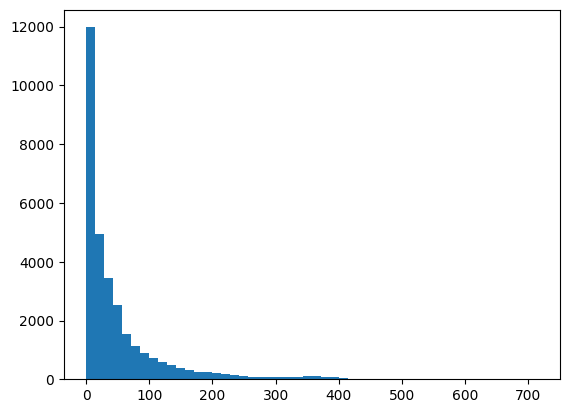

In [47]:
plt.hist(interpurchase_gaps['GapDays'].to_list(), bins=50)
plt.show()

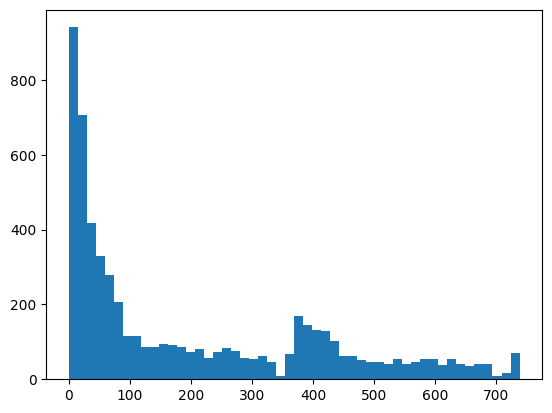

In [48]:
plt.hist(last_date_purchase['last purchase'].to_list(), bins=50)
plt.show()

In [49]:
import polars as pl
from datetime import timedelta

purchases = (
    customer_data
    .filter(
        pl.col("Customer ID").is_not_null()
        & ~pl.col("Invoice").str.starts_with("C").fill_null(False)
        & (pl.col("Quantity") > 0)
        & (pl.col("Price") > 0)
        & pl.col("InvoiceDate").is_not_null()
    )
    .group_by(["Customer ID", "Invoice"])
    .agg(
        pl.col("InvoiceDate").min().cast(pl.Date).alias("InvoiceDate")
    )
    .sort(["Customer ID", "InvoiceDate"])
)

min_date = purchases.select(
    pl.col("InvoiceDate").min(),
).row(0)[0]

max_date = purchases.select(
    pl.col("InvoiceDate").max()
).row(0)[0]
print("First purchase date:", min_date)
print("Last purchase date:", max_date)
print("Unique customer-invoice events:", purchases.height)

First purchase date: 2009-12-01
Last purchase date: 2011-12-09
Unique customer-invoice events: 36969


In [50]:
thresholds = [90, 180, 270]
horizons = [90, 180]

# Leave enough historical data before each cutoff
# and enough future data to evaluate the longest horizon.
start_cutoff = min_date + timedelta(days=180)
end_cutoff = max_date - timedelta(days=max(horizons))

# Evaluate several historical cutoffs, 90 days apart.
cutoffs = []
cutoff = start_cutoff

while cutoff <= end_cutoff:
    cutoffs.append(cutoff)
    cutoff += timedelta(days=90)

if not cutoffs:
    raise ValueError(
        "Not enough date coverage for the selected history "
        "and future windows. Reduce the minimum history or horizons."
    )

results = []

for cutoff in cutoffs:
    # Customer population known by the historical cutoff.
    historical = (
        purchases
        .filter(pl.col("InvoiceDate") <= cutoff)
        .group_by("Customer ID")
        .agg(
            pl.col("InvoiceDate").max().alias("last_purchase_date")
        )
        .with_columns(
            (
                pl.lit(cutoff) - pl.col("last_purchase_date")
            ).dt.total_days().alias("recency_days")
        )
    )

    # Purchases after the cutoff, within each evaluation window.
    for horizon in horizons:
        future_end = cutoff + timedelta(days=horizon)

        future_purchases = (
            purchases
            .filter(
                (pl.col("InvoiceDate") > cutoff)
                & (pl.col("InvoiceDate") <= future_end)
            )
            .group_by("Customer ID")
            .agg(
                pl.len().alias("future_invoice_count")
            )
        )

        evaluated = (
            historical
            .join(future_purchases, on="Customer ID", how="left")
            .with_columns(
                pl.col("future_invoice_count").fill_null(0),
                (
                    pl.col("future_invoice_count")
                    .fill_null(0) == 0
                ).alias("no_future_purchase")
            )
        )

        for threshold in thresholds:
            scored = evaluated.with_columns(
                (
                    pl.col("recency_days") >= threshold
                ).alias("predicted_inactive")
            )

            # Treat "no purchase during the future window"
            # as the outcome we want the threshold to predict.
            counts = scored.select(
                (
                    pl.col("predicted_inactive")
                    & pl.col("no_future_purchase")
                ).sum().alias("tp"),
                (
                    pl.col("predicted_inactive")
                    & ~pl.col("no_future_purchase")
                ).sum().alias("fp"),
                (
                    ~pl.col("predicted_inactive")
                    & pl.col("no_future_purchase")
                ).sum().alias("fn"),
                (
                    ~pl.col("predicted_inactive")
                    & ~pl.col("no_future_purchase")
                ).sum().alias("tn"),
            ).row(0, named=True)

            tp, fp, fn, tn = (
                int(counts[k] or 0)
                for k in ("tp", "fp", "fn", "tn")
            )

            precision = tp / (tp + fp) if tp + fp else 0.0
            recall = tp / (tp + fn) if tp + fn else 0.0
            specificity = tn / (tn + fp) if tn + fp else 0.0

            f1 = (
                2 * precision * recall / (precision + recall)
                if precision + recall else 0.0
            )

            balanced_accuracy = (recall + specificity) / 2

            results.append({
                "cutoff": cutoff,
                "horizon_days": horizon,
                "threshold_days": threshold,
                "customers": scored.height,
                "inactive_pct": (
                    scored["predicted_inactive"].mean() * 100
                ),
                "no_future_purchase_pct": (
                    scored["no_future_purchase"].mean() * 100
                ),
                "precision": precision,
                "recall": recall,
                "f1": f1,
                "balanced_accuracy": balanced_accuracy,
            })

per_cutoff = pl.DataFrame(results).sort(
    ["horizon_days", "threshold_days", "cutoff"]
)

print(per_cutoff)

shape: (30, 10)
┌────────────┬───────────┬───────────┬───────────┬───┬───────────┬──────────┬──────────┬───────────┐
│ cutoff     ┆ horizon_d ┆ threshold ┆ customers ┆ … ┆ precision ┆ recall   ┆ f1       ┆ balanced_ │
│ ---        ┆ ays       ┆ _days     ┆ ---       ┆   ┆ ---       ┆ ---      ┆ ---      ┆ accuracy  │
│ date       ┆ ---       ┆ ---       ┆ i64       ┆   ┆ f64       ┆ f64      ┆ f64      ┆ ---       │
│            ┆ i64       ┆ i64       ┆           ┆   ┆           ┆          ┆          ┆ f64       │
╞════════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪══════════╪══════════╪═══════════╡
│ 2010-05-30 ┆ 90        ┆ 90        ┆ 2703      ┆ … ┆ 0.698507  ┆ 0.341357 ┆ 0.458599 ┆ 0.594853  │
│ 2010-08-28 ┆ 90        ┆ 90        ┆ 3308      ┆ … ┆ 0.571116  ┆ 0.56129  ┆ 0.566161 ┆ 0.62696   │
│ 2010-11-26 ┆ 90        ┆ 90        ┆ 4235      ┆ … ┆ 0.837993  ┆ 0.42005  ┆ 0.559598 ┆ 0.632201  │
│ 2011-02-24 ┆ 90        ┆ 90        ┆ 4518      ┆ … ┆ 0.778297  ┆ 0.736484

In [51]:
summary = (
    per_cutoff
    .group_by(["horizon_days", "threshold_days"])
    .agg(
        pl.col("customers").mean().round(0).alias("avg_customers"),
        pl.col("inactive_pct").mean().round(2).alias("avg_inactive_pct"),
        pl.col("no_future_purchase_pct")
        .mean().round(2).alias("avg_no_purchase_pct"),
        pl.col("precision").mean().round(3).alias("mean_precision"),
        pl.col("recall").mean().round(3).alias("mean_recall"),
        pl.col("f1").mean().round(3).alias("mean_f1"),
        pl.col("balanced_accuracy")
        .mean().round(3).alias("mean_balanced_accuracy"),
        pl.col("balanced_accuracy")
        .std().round(3).alias("std_balanced_accuracy"),
    )
    .sort(["horizon_days", "threshold_days"])
)

print(summary.glimpse())

Rows: 6
Columns: 10
$ horizon_days           <i64> 90, 90, 90, 180, 180, 180
$ threshold_days         <i64> 90, 180, 270, 90, 180, 270
$ avg_customers          <f64> 3937.0, 3937.0, 3937.0, 3937.0, 3937.0, 3937.0
$ avg_inactive_pct       <f64> 44.11, 20.61, 8.62, 44.11, 20.61, 8.62
$ avg_no_purchase_pct    <f64> 58.13, 58.13, 58.13, 43.67, 43.67, 43.67
$ mean_precision         <f64> 0.742, 0.808, 0.678, 0.601, 0.68, 0.604
$ mean_recall            <f64> 0.559, 0.277, 0.116, 0.602, 0.306, 0.139
$ mean_f1                <f64> 0.624, 0.382, 0.188, 0.593, 0.386, 0.211
$ mean_balanced_accuracy <f64> 0.648, 0.596, 0.544, 0.648, 0.597, 0.554
$ std_balanced_accuracy  <f64> 0.045, 0.073, 0.047, 0.037, 0.07, 0.057

None


In [52]:
customer_no = customer_data.group_by('Customer ID').agg(pl.col("Invoice").n_unique().alias('No. of transaction')).sort('No. of transaction', descending=True)

In [53]:
customer_no.select(
    pl.col('No. of transaction').median().alias('median'),
        pl.col("No. of transaction").quantile(0.75).alias("p75"),
        pl.col("No. of transaction").quantile(0.90).alias("p90"),
        pl.col("No. of transaction").quantile(0.95).alias("p95"),
        pl.col("No. of transaction").max().alias("Max")

)

median,p75,p90,p95,Max
f64,f64,f64,f64,u32
4.0,8.0,17.0,26.0,510


In [54]:
customer_no = customer_data.group_by('Customer ID')\
    .agg(
        pl.len().alias('invoice_lines'),
        pl.col("Invoice").n_unique().alias('unique_invoices'), 
        pl.col("InvoiceDate").dt.replace_time_zone(None).n_unique().alias('purchase_days')
    )

In [55]:
print(
    customer_no.select(
        pl.col("invoice_lines").median().alias("median_lines"),
        pl.col("unique_invoices").median().alias("median_invoices"),
        pl.col("purchase_days").median().alias("median_purchase_days"),
    )
)

shape: (1, 3)
┌──────────────┬─────────────────┬──────────────────────┐
│ median_lines ┆ median_invoices ┆ median_purchase_days │
│ ---          ┆ ---             ┆ ---                  │
│ f64          ┆ f64             ┆ f64                  │
╞══════════════╪═════════════════╪══════════════════════╡
│ 52.0         ┆ 4.0             ┆ 4.0                  │
└──────────────┴─────────────────┴──────────────────────┘


In [56]:
customer_data = customer_data.drop(['is_operational_annotation'])

In [57]:
customer_data = customer_data.with_columns(
    pl.when(
        pl.col("CorrectedStockCode").is_not_null()
    )
    .then(pl.col("CorrectedStockCode"))
    .otherwise(pl.col("StockCode"))
    .alias("Product ID")
)

In [58]:
customer_data = customer_data.with_columns(
    pl.when(pl.col('Invoice').str.starts_with('C')).then(True).otherwise(False).alias('is_cancelation')
)

customer_data = customer_data.drop('CorrectedStockCode', 'OriginalStockCode', 'Product ID')

In [59]:
customer_data.filter(pl.col('is_cancelation') == True)

Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,is_cancelation
str,str,str,i64,datetime[ms],f64,i64,str,bool
"""C518669""","""22077""","""6 RIBBONS RUSTIC CHARM""",-12,2010-08-10 15:16:00,1.65,13004,"""United Kingdom""",true
"""C496116""","""M""","""Manual""",-1,2010-01-29 11:05:00,8985.6,17949,"""United Kingdom""",true
"""C509036""","""84795D""","""SEASIDE STRIPE HAMMOCK""",-1,2010-05-20 09:32:00,6.95,15614,"""United Kingdom""",true
"""C517068""","""22329""","""ROUND CONTAINER SET OF 5 RETRO…",-12,2010-07-26 13:46:00,1.65,16555,"""United Kingdom""",true
"""C540164""","""35400""","""WOODEN BOX ADVENT CALENDAR """,-2,2011-01-05 12:02:00,8.95,14911,"""EIRE""",true
…,…,…,…,…,…,…,…,…
"""C543636""","""22727""","""ALARM CLOCK BAKELIKE RED """,-1,2011-02-10 16:34:00,3.75,13767,"""United Kingdom""",true
"""C569985""","""71053""","""WHITE METAL LANTERN""",-8,2011-10-06 19:51:00,3.75,15365,"""United Kingdom""",true
"""C504468""","""22198""","""LARGE POPCORN HOLDER """,-3,2010-04-13 17:40:00,1.65,15329,"""United Kingdom""",true


In [60]:
# customer_data.write_excel('../../data/online_retail_II_cleaned.xlsx')

In [61]:
# customer_data.write_csv('../../data/online_retail_II_cleaned.csv')

In [62]:
customer_data.filter(pl.col('Quantity') < 0)

Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,is_cancelation
str,str,str,i64,datetime[ms],f64,i64,str,bool
"""C518669""","""22077""","""6 RIBBONS RUSTIC CHARM""",-12,2010-08-10 15:16:00,1.65,13004,"""United Kingdom""",true
"""C496116""","""M""","""Manual""",-1,2010-01-29 11:05:00,8985.6,17949,"""United Kingdom""",true
"""C509036""","""84795D""","""SEASIDE STRIPE HAMMOCK""",-1,2010-05-20 09:32:00,6.95,15614,"""United Kingdom""",true
"""C517068""","""22329""","""ROUND CONTAINER SET OF 5 RETRO…",-12,2010-07-26 13:46:00,1.65,16555,"""United Kingdom""",true
"""C540164""","""35400""","""WOODEN BOX ADVENT CALENDAR """,-2,2011-01-05 12:02:00,8.95,14911,"""EIRE""",true
…,…,…,…,…,…,…,…,…
"""C543636""","""22727""","""ALARM CLOCK BAKELIKE RED """,-1,2011-02-10 16:34:00,3.75,13767,"""United Kingdom""",true
"""C569985""","""71053""","""WHITE METAL LANTERN""",-8,2011-10-06 19:51:00,3.75,15365,"""United Kingdom""",true
"""C504468""","""22198""","""LARGE POPCORN HOLDER """,-3,2010-04-13 17:40:00,1.65,15329,"""United Kingdom""",true


In [63]:
product_catalogue = (
    customer_data
    .filter(pl.col("StockCode").is_not_null())
    .group_by("StockCode")
    .agg(
        pl.col("Description")
        .drop_nulls()
        .mode()
        .first()
        .alias("Description")
    )
)

In [64]:
product_catalogue

StockCode,Description
str,str
"""78056""","""CAMOUFLAGE BACKPACK ON WHEELS"""
"""22415""","""WHITE TISSUE REAM"""
"""81953B""","""ROUND BLUE CLOCK WITH SUCKER"""
"""21304""","""ARCHED GREY MIRROR"""
"""16169C""","""WRAP BLUE REINDEER"""
…,…
"""22962""","""JAM JAR WITH PINK LID"""
"""23153""","""ZINC SWEETHEART WIRE LETTER RA…"
"""84678""","""CLASSICAL ROSE SMALL VASE"""


In [65]:
import re

CATEGORY_RULES = [
    ("Gift Wrapping", r"\b(WRAP|RIBBON|GIFT BAG|GIFT TAG)\b"),
    ("Bags & Accessories", r"\b(BAG|PURSE|WALLET)\b"),
    ("Paper & Stationery", r"\b(PAPER|NOTEBOOK|PEN|PENCIL|CARD)\b"),
    ("Kitchenware", r"\b(MUG|CUP|PLATE|BOWL|CAKESTAND)\b"),
    ("Lighting & Candle Holders", r"\b(LAMP|LIGHT|CANDLE|T-LIGHT HOLDER)\b"),
    ("Seasonal Products", r"\b(CHRISTMAS|EASTER|HALLOWEEN)\b"),
]

def assign_category(description):
    if description is None:
        return "Unclassified"

    text = description.upper()

    for category, pattern in CATEGORY_RULES:
        if re.search(pattern, text):
            return category

    return "Unclassified"

product_catalogue = product_catalogue.with_columns(
    pl.col("Description")
    .map_elements(assign_category, return_dtype=pl.String)
    .alias("Category")
)

In [66]:
product_catalogue['Category'].value_counts()

Category,count
str,u32
"""Bags & Accessories""",198
"""Gift Wrapping""",106
"""Lighting & Candle Holders""",286
"""Kitchenware""",218
"""Seasonal Products""",201
"""Paper & Stationery""",246
"""Unclassified""",3391


In [67]:
product_catalogue

StockCode,Description,Category
str,str,str
"""78056""","""CAMOUFLAGE BACKPACK ON WHEELS""","""Unclassified"""
"""22415""","""WHITE TISSUE REAM""","""Unclassified"""
"""81953B""","""ROUND BLUE CLOCK WITH SUCKER""","""Unclassified"""
"""21304""","""ARCHED GREY MIRROR""","""Unclassified"""
"""16169C""","""WRAP BLUE REINDEER""","""Gift Wrapping"""
…,…,…
"""22962""","""JAM JAR WITH PINK LID""","""Unclassified"""
"""23153""","""ZINC SWEETHEART WIRE LETTER RA…","""Unclassified"""
"""84678""","""CLASSICAL ROSE SMALL VASE""","""Unclassified"""


In [68]:
import numpy as np
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

descriptions = product_catalogue["Description"].to_list()

valid_indices = [
    i for i, desc in enumerate(descriptions)
    if desc is not None and desc.strip()
]

texts = [descriptions[i] for i in valid_indices]

embeddings = model.encode(
    texts,
    normalize_embeddings=True,
    show_progress_bar=True,
    batch_size=64,
)

/home/clyde/anaconda3/envs/self-driving-cars/lib/python3.12/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.6.0)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/73 [00:00<?, ?it/s]

In [69]:
product_catalogue.shape[0] * 0.02

92.92

In [70]:
47 // 2

23

In [71]:
from sklearn.preprocessing import normalize

normalized_embeddings = normalize(embeddings, norm='l2')

In [72]:
import hdbscan

clusterer = hdbscan.HDBSCAN(min_cluster_size = 50, min_samples = 5, metric = "euclidean")

In [73]:
labels = clusterer.fit_predict(normalized_embeddings)

In [74]:
product_catalogue = product_catalogue.with_columns(pl.Series(labels).alias('cluster_label'))

In [75]:
product_catalogue['cluster_label'].value_counts()

cluster_label,count
i64,u32
1,59
0,2656
-1,1931


In [76]:
import umap

reducer = umap.UMAP(random_state=1)
reduced_embedding = reducer.fit_transform(normalized_embeddings)

I0000 00:00:1792412036.924088  406889 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/home/clyde/anaconda3/envs/self-driving-cars/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


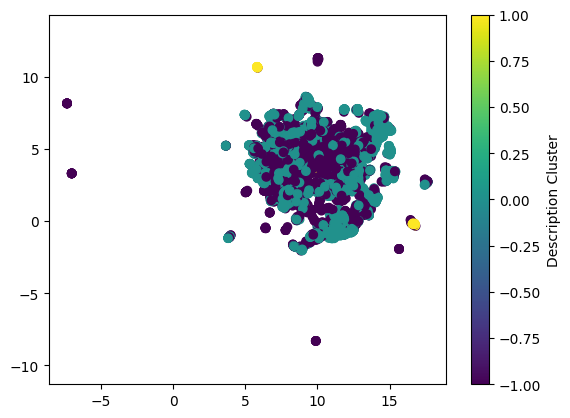

In [77]:
plt.scatter(reduced_embedding[:, 0], reduced_embedding[:, 1], c=labels)
plt.gca().set_aspect('equal', 'datalim')
plt.colorbar(label="Description Cluster")
plt.show()

In [78]:
rules = [
    ("Seasonal & Christmas",   ["CHRISTMAS", "XMAS", "EASTER", "SANTA", "ADVENT", "SNOWFLAKE", "REINDEER", "SNOWMAN", "HALLOWEEN", "STOCKING"]),
    ("Candles & Fragrance",    ["CANDLE", "INCENSE", "VOTIVE", "T-LIGHT", "TEA LIGHT", "TEALIGHT", "OIL BURNER", "POTPOURRI", "FRAGRANCE", "SCENTED"]),
    ("Jewellery & Accessories",["NECKLACE", "BRACELET", "EARRING", "RING", "CHARM", "BEAD", "BROOCH", "HAIR", "DIAMANTE", "SCARF", "UMBRELLA"]),
    ("Bags & Purses",          ["BAG", "PURSE", "SHOPPER", "WALLET", "BACKPACK", "SATCHEL"]),
    ("Toys, Kids & Party",     ["TOY", "DOLL", "GAME", "PUZZLE", "CHILD", "KIDS", "BALLOON", "PARTY", "TEDDY", "SPACEBOY", "DOLLY", "PLAYING", "BUNTING", "PIRATE"]),
    ("Stationery & Wrapping",  ["CARD", "WRAP", "PAPER", "NOTEBOOK", "PENCIL", "PEN ", "STICKER", "RIBBON", "ENVELOPE", "GIFT TAG", "BOOK", "ALBUM", "ERASER", "CRAYON", "TAPE"]),
    ("Kitchen & Dining",       ["MUG", "CUP", "TEA", "PLATE", "BOWL", "CAKE", "SPOON", "CUTLERY", "TEAPOT", "BAKING", "APRON", "JAM", "KITCHEN", "COASTER", "PLACEMAT", "LUNCH", "GLASS", "JUG", "KNIFE", "FORK", "SPICE", "TOWEL"]),
    ("Lighting",               ["LIGHT", "LAMP", "LANTERN", "BULB", "FAIRY"]),
    ("Garden & Outdoor",       ["GARDEN", "PLANT", "WATERING", "BIRD", "TROWEL", "SEED", "PARASOL", "WINDMILL", "POT ", "FLOWER POT"]),
    ("Storage & Boxes",        ["BOX", "TIN", "BASKET", "STORAGE", "TRUNK", "CASE", "TUBE", "BOTTLE", "JAR", "TRAY", "CRATE"]),
    ("Home Decor",             ["FRAME", "MIRROR", "CLOCK", "SIGN", "WALL", "CUSHION", "DOORMAT", "HOOK", "DRAWER", "CABINET", "SHELF",
                                "VASE", "DECORATION", "HANGING", "DOOR", "TILE", "RACK", "STOOL", "CHAIR", "TABLE", "HEART", "FLOWER", "STAR"]),
]
def find_category(text):
    text = str(text).upper()
    for category, words in rules:
        for w in words:
            if w in text:
                return category
    return "Other"

product_catalogue = product_catalogue.with_columns(pl.col("Description").map_elements(find_category).alias("Category"))


In [79]:
product_catalogue['Category'].value_counts().show(None)

Category,count
str,u32
"""Lighting""",97
"""Other""",638
"""Candles & Fragrance""",415
"""Jewellery & Accessories""",542
"""Storage & Boxes""",303
"""Home Decor""",782
"""Seasonal & Christmas""",265
"""Kitchen & Dining""",576
"""Bags & Purses""",218


In [85]:
customer_data_orig = customer_data.drop("StockCode_right", "Category", "cluster_label")


In [86]:
product_catalogue.shape

(4646, 4)

In [88]:
customer_data_orig['StockCode'].n_unique()

4646

In [90]:
customer_data_1 = customer_data_orig.join(product_catalogue, "StockCode", "left")

In [91]:
customer_data_1['Category'].null_count()

0

In [92]:
customer_data_1.write_excel('../../data/online_retail_II_cleaned.xlsx')
customer_data_1.write_csv('../../data/online_retail_II_cleaned.csv')